# Fig 5. Falsification by inclusion

Fig 5: falsification-by-inclusion and its lagged-only replication. Temperature never
displaces PM2.5, in two runs whose candidate pools barely overlap.

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()          # notebooks/ folder
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from fig_common import draw_termmap
from termmap_utils import DATA, load_front, term_presence
from style import *   # PM25, O3, NAVY, GREY, RED, LIGHT, ROOT, DATA_OUT, save_fig, panel_label

In [2]:
# Settings (edit here, then Run All)
# Portrait layout (2026-09-23): (a) on top, (b) below -- pages are taller than wide, and each term map is
# itself wide/short (25 complexity columns, ~7-8 variable rows), so stacking suits a portrait page better.
# Figsize shrunk and fonts bumped 2026-09-24 (user: text reads small once scaled to the page's textwidth).
S = dict(figsize=(8.0, 10.4), hspace=0.62,   # 2026-10-06: three panels (constrained front of the lead equation added on top)
          max_complexity=25, label_size=8, fontsize=9.5,
         bracket_lw=1.4, bracket_colour=NAVY, note_fontsize=8.5)
MARK_COLOURS = dict(pm25=PM25, temp=RED)      # highlighted rows in the term maps

In [3]:
# Analysis
B = DATA / "bogota"
# 2026-10-06: the O3 lead equation now comes from the dimensionally constrained front with temperature in the pool, so
# the test is shown on that front first, then on the free-form front from the same pool, then on the lagged-only pool.
lead = load_front(B / "bogota_o3_pysr_units_fire2_pm_pareto_front_seed0.csv")
left = load_front(B / "bogota_o3_temp_pm_falsification_pareto.csv")   # 2026-10-20: free form with PM2.5 AND temperature offered (the corrected-fire selection no longer picks PM2.5)
right = load_front(B / "bogota_o3_forecast_interpretable_pysr_pareto.csv")

from termmap_utils import equation_variables

def sustained(front, a, b):
    """2026-10-20: smallest complexity c* such that EVERY equation with complexity >= c* contains PM2.5 (`a`); also reports at which
    complexities temperature (`b`) appears and in how many equations it appears together with PM2.5. (Before the fire-file correction the
    statistic required both variables to be present together.)"""
    rows = [(int(r.complexity), a in equation_variables(r.equation), b in equation_variables(r.equation))
            for r in front.sort_values("complexity").itertuples()]
    cstar = None
    for c, ha, hb in rows:
        if all(x for cc, x, y in rows if cc >= c):
            cstar = c
            break
    n_from = sum(1 for c, _, _ in rows if cstar is not None and c >= cstar)
    b_without_a = [c for c, ha, hb in rows if hb and not ha]
    both = [c for c, ha, hb in rows if ha and hb]
    return dict(sustained_from=cstar, n_equations_from=n_from, max_complexity=rows[-1][0], temp_without_pm25_at=b_without_a,
                temp_present_at=[c for c, ha, hb in rows if hb], n_with_both=len(both), pm25_lowest_complexity=min([c for c, ha, hb in rows if ha] or [None]))

In [4]:
# Coexistence statistic
cc = sustained(lead, "pm25", "temp_2m")
cl = sustained(left, "pm25", "temp_2m")
cr = sustained(right, "pm25_lag1", "temp_2m_lag2")   # 2026-10-20: the re-run lagged-only selection no longer contains lagged PM2.5, so this panel shows its absence
print("constrained:", cc, "| free form:", cl, "| lagged-only:", cr)
pd.DataFrame([
    dict(run="same-day, PM2.5 and temp_2m in pool, dimensionally constrained (lead equation's front)", pair="pm25 & temp_2m", **cc),
    dict(run="same-day, PM2.5 and temp_2m in pool, free form", pair="pm25 & temp_2m", **cl),
    dict(run="lagged-only (no same-day, no self-lag, no calendar)", pair="pm25_lag1 & temp_2m_lag2", **cr),
]).to_csv(DATA_OUT / "falsification_coexistence.csv", index=False)

constrained: {'sustained_from': 9, 'n_equations_from': 10, 'max_complexity': 23, 'temp_without_pm25_at': [], 'temp_present_at': [], 'n_with_both': 0, 'pm25_lowest_complexity': 4} | free form: {'sustained_from': 7, 'n_equations_from': 13, 'max_complexity': 25, 'temp_without_pm25_at': [], 'temp_present_at': [5, 7, 11, 13, 14, 16, 18, 20, 22, 24, 25], 'n_with_both': 11, 'pm25_lowest_complexity': 5} | lagged-only: {'sustained_from': None, 'n_equations_from': 0, 'max_complexity': 25, 'temp_without_pm25_at': [], 'temp_present_at': [], 'n_with_both': 0, 'pm25_lowest_complexity': None}


saved /path/to/project/Paper/figures/fig05_falsification_by_inclusion.png


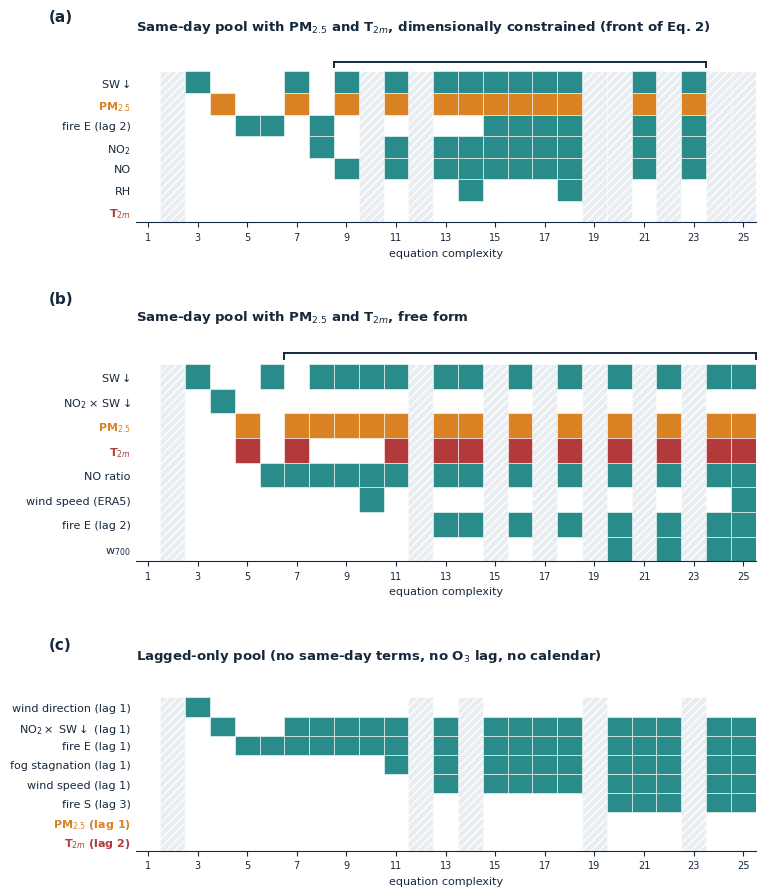

In [5]:
# Figure
fig, axes = plt.subplots(3, 1, figsize=S['figsize'], gridspec_kw=dict(hspace=S['hspace'], height_ratios=[len(term_presence(f)) + 1 for f in (lead, left, right)]))
for ax, front, pair, c, letter, ttl in [
    (axes[0], lead, ("pm25", "temp_2m"), cc, "a", "Same-day pool with PM$_{2.5}$ and T$_{2m}$, dimensionally constrained (front of Eq. 2)"),
    (axes[1], left, ("pm25", "temp_2m"), cl, "b", "Same-day pool with PM$_{2.5}$ and T$_{2m}$, free form"),
    (axes[2], right, ("pm25_lag1", "temp_2m_lag2"), cr, "c", "Lagged-only pool (no same-day terms, no O$_3$ lag, no calendar)")]:
    present = list(term_presence(front).index)
    rows_ = present + [p for p in pair if p not in present]            # keep the PM2.5 / temperature rows even where they never appear
    mat = draw_termmap(ax, front, O3, rows=rows_, max_c=S['max_complexity'], mark_rows={pair[0]: MARK_COLOURS['pm25'], pair[1]: MARK_COLOURS['temp']}, label_size=S['label_size'])
    ax.set_title(ttl, fontsize=S['fontsize'], loc="left", pad=14)
    panel_label(ax, letter, x=-0.14, y=1.15)
    # bracket: complexities from which every equation contains PM2.5 (only if there is such a stretch)
    ax.set_ylim(len(mat) - 0.5, -1.5)
    if c["sustained_from"] is not None:
        lo, hi = c["sustained_from"], c["max_complexity"]
        ax.plot([lo - 0.5, hi + 0.5], [-0.95, -0.95], color=S['bracket_colour'], lw=S['bracket_lw'], clip_on=False)
        ax.plot([lo - 0.5, lo - 0.5], [-0.95, -0.7], color=S['bracket_colour'], lw=S['bracket_lw'], clip_on=False)
        ax.plot([hi + 0.5, hi + 0.5], [-0.95, -0.7], color=S['bracket_colour'], lw=S['bracket_lw'], clip_on=False)
save_fig(fig, "fig05_falsification_by_inclusion")